In [103]:
from sklearn.datasets import make_regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [104]:
X, y = make_regression(n_samples = 4, n_features=1, n_informative = 1, n_targets=1, noise =80, random_state=13)

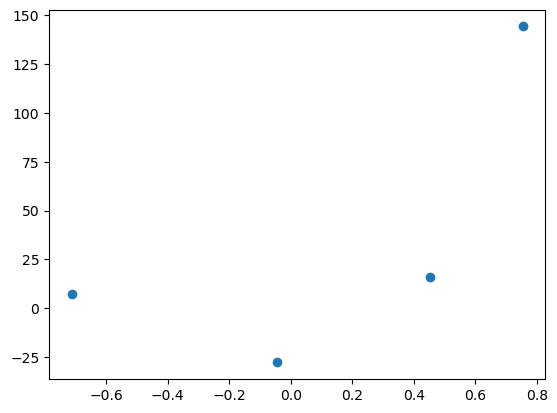

In [105]:
plt.scatter(X,y)

In [106]:
from sklearn.linear_model import LinearRegression as LR

In [107]:
reg = LR()
reg.fit(X,y)

LinearRegression()

In [108]:
reg.coef_

array([78.35063668])

In [109]:
reg.intercept_

26.15963284313262

In [110]:
x_input = np.linspace(-1,2,5)

In [111]:
x_input

array([-1.  , -0.25,  0.5 ,  1.25,  2.  ])

In [112]:
y_input = reg.coef_*x_input + reg.intercept_

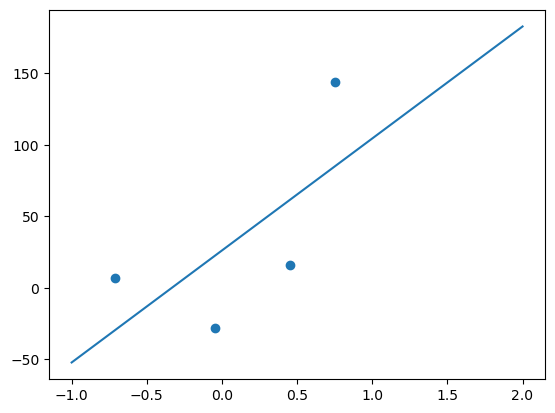

In [113]:
plt.plot(x_input, y_input)
plt.scatter(X,y)

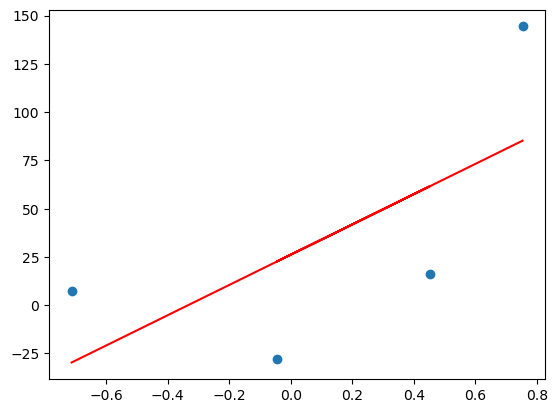

In [114]:
plt.scatter(X,y)
plt.plot(X, reg.predict(X), color = 'red')

In [115]:
# Let's apply gradient descent assuming slope is constant i.e m = 78.35
# Ands, assume the starting value of b is 0
b=0

In [116]:
y_pred = ((78.35 * X) + b).reshape(4)

In [117]:
y_pred

array([-55.81580837,  35.39949674,  -3.48681619,  59.05759577])

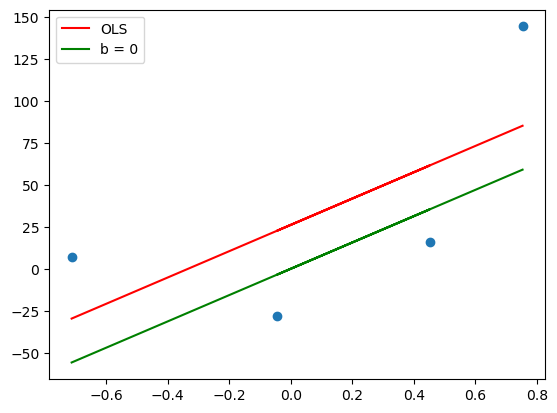

In [118]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X), color = 'red', label='OLS')
plt.plot(X, y_pred, color = 'green', label = 'b = 0')
plt.legend()
plt.show()

In [119]:
m = 78.35
b = 0

In [120]:
X

array([[-0.71239066],
       [ 0.45181234],
       [-0.04450308],
       [ 0.75376638]])

In [121]:
y

array([  7.21786552,  16.04609925, -27.83756166, 144.36688189])

In [122]:
x = x.reshape(4)
x

array([-0.71239066,  0.45181234, -0.04450308,  0.75376638])

In [123]:
loss_slope = (-2*(y - m*x)).sum()

In [124]:
loss_slope

-209.27763408209216

In [125]:
lr = 0.1
step_size = lr*loss_slope
step_size

-20.927763408209216

In [126]:
b = b - step_size
b

20.927763408209216

In [127]:
y_pred1 = m*x+b

In [128]:
y_pred1

array([-34.88804496,  56.32726015,  17.44094722,  79.98535918])

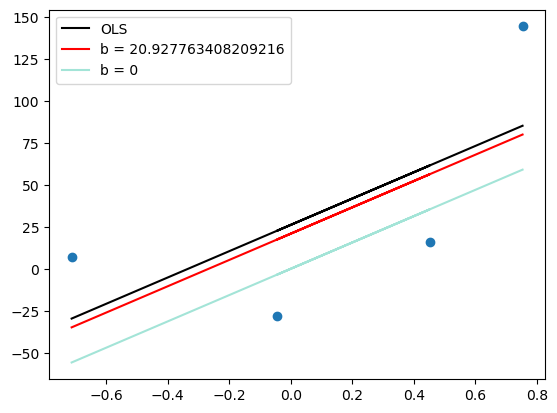

In [129]:
plt.scatter(X,y)
plt.plot(X, reg.predict(X), color = 'black', label = 'OLS')
plt.plot(x, y_pred1, color = 'red', label = 'b = {}'.format(b))
plt.plot(x, y_pred, color = '#A3E4D7', label = 'b = 0')
plt.legend()
plt.show()

In [130]:
b

20.927763408209216

In [131]:
loss_slope = -2*(y-m*x-b).sum()
loss_slope


-41.85552681641843

In [132]:
step_size = loss_slope*lr
step_size

-4.185552681641844

In [133]:
b = b - step_size
b

25.11331608985106

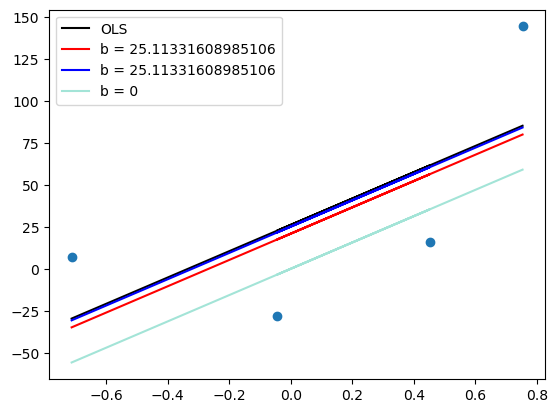

In [134]:
y_pred2 = m*x+b

plt.scatter(X,y)
plt.plot(X, reg.predict(X), color = 'black', label = 'OLS')
plt.plot(x, y_pred1, color = 'red', label = 'b = {}'.format(b))
plt.plot(x, y_pred2, color = 'blue', label = 'b = {}'.format(b))
plt.plot(x, y_pred, color = '#A3E4D7', label = 'b = 0')
plt.legend()
plt.show()

In [135]:
b

25.11331608985106

## Now by using loops

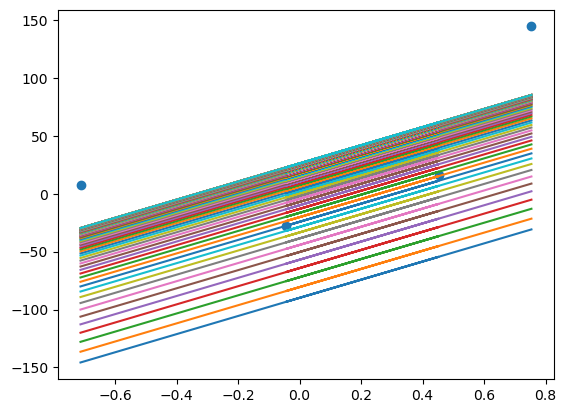

In [141]:
b = -100
m = 78.35
lr = 0.01
epochs = 100

for i in range(epochs):
    loss_slope = -2*np.sum(y-m*X.ravel()-b)
    b = b-(lr*loss_slope)
    y_pred = m*X + b
    plt.plot(X,y_pred)
    
plt.scatter(X,y)